# Mobile Game A/B Test: Moving the Progress Gate (Cookie Cats)

**Author:** Utkarsh Chaudhari
**Data:** Kaggle "Mobile Games A/B Testing - Cookie Cats" (90,189 players)

## Business question
In Cookie Cats, players hit a *gate* that forces a wait (or an in-app purchase) before they can continue.
The team tested moving the first gate from **level 30** (control, `gate_30`) to **level 40** (treatment, `gate_40`).

**Decision to make:** should the gate move to level 40?

**Primary metric:** 7-day retention (did the player come back 7 days after install).
**Secondary metrics:** 1-day retention, game rounds played in the first 14 days.
**Unit of randomisation:** player (assigned at install).

## Hypotheses
- H0: retention is the same under both gate positions.
- H1: retention differs (two-sided test, alpha = 0.05).

In [1]:
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep, proportion_effectsize
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")
RNG = np.random.default_rng(42)
OUT = "charts"
import os; os.makedirs(OUT, exist_ok=True)
RESULTS = {}

# Chart style: validated categorical palette (slot 1 blue, slot 2 orange), recessive axes
C30, C40 = "#2a78d6", "#eb6834"
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 11, "axes.titlesize": 13,
    "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "legend.frameon": False, "figure.dpi": 110,
})
def save(fig, name):
    fig.tight_layout(); fig.savefig(f"{OUT}/{name}.png", dpi=160, bbox_inches="tight"); plt.show()

## 1. Load and validate the data

In [2]:
df = pd.read_csv("data/cookie_cats.csv")
print(df.shape)
print(df.dtypes)
print("Nulls:", int(df.isna().sum().sum()), "| Duplicate user IDs:", int(df.userid.duplicated().sum()))
df.head()

(90189, 5)
userid            int64
version             str
sum_gamerounds    int64
retention_1        bool
retention_7        bool
dtype: object
Nulls: 0 | Duplicate user IDs: 0


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [3]:
df.groupby("version").agg(players=("userid", "count"),
                          mean_rounds=("sum_gamerounds", "mean"),
                          median_rounds=("sum_gamerounds", "median"),
                          max_rounds=("sum_gamerounds", "max"),
                          ret_1=("retention_1", "mean"),
                          ret_7=("retention_7", "mean")).round(4)

,players,mean_rounds,median_rounds,max_rounds,ret_1,ret_7
version,,,,,,
gate_30,44700,52.4563,17.0,49854,0.4482,0.1902
gate_40,45489,51.2988,16.0,2640,0.4423,0.1820


### Outlier check
One player in `gate_30` logged ~50,000 rounds in 14 days, roughly 20x the next highest player. That is almost certainly a bot or logging error.
It does not affect retention (a binary metric), but it distorts any mean-based analysis of game rounds, so it is removed from the rounds analysis only.

In [4]:
top = df.sort_values("sum_gamerounds", ascending=False).head(3)[["userid","version","sum_gamerounds"]]
print(top)
outlier_ids = df.loc[df.sum_gamerounds > 10000, "userid"]
df_r = df[~df.userid.isin(outlier_ids)].copy()
print(f"Removed {len(outlier_ids)} outlier(s) from the rounds analysis.")
zero = (df.sum_gamerounds == 0).mean()
print(f"Players who installed but never played a round: {zero:.1%}")
RESULTS["n_total"] = int(len(df)); RESULTS["zero_round_share"] = round(float(zero), 4)

        userid  version  sum_gamerounds
57702  6390605  gate_30           49854
7912    871500  gate_30            2961
29417  3271615  gate_40            2640
Removed 1 outlier(s) from the rounds analysis.
Players who installed but never played a round: 4.4%


## 2. Sample ratio mismatch (SRM) check
Before trusting any result, check that the split between groups matches the intended 50/50 design.
A significant imbalance usually points to a bug in assignment or logging.

In [5]:
counts = df.version.value_counts().reindex(["gate_30", "gate_40"])
chi2, p_srm = stats.chisquare(counts, f_exp=[len(df)/2]*2)
print(counts.to_dict(), f"| share gate_30 = {counts['gate_30']/len(df):.4f}")
print(f"SRM chi-square = {chi2:.2f}, p = {p_srm:.4f}")
RESULTS["srm"] = {"gate_30": int(counts["gate_30"]), "gate_40": int(counts["gate_40"]),
                  "chi2": round(float(chi2), 2), "p": round(float(p_srm), 4)}

{'gate_30': 44700, 'gate_40': 45489} | share gate_30 = 0.4956
SRM chi-square = 6.90, p = 0.0086


**Reading:** the split is 49.6% / 50.4% and the chi-square test does flag it (p < 0.01). With 90k users, a 0.9 pp gap is statistically detectable.
In production this would trigger an investigation before shipping. Here the original assignment logic is not available, and the imbalance is small relative to the effect we test,
so the analysis proceeds with that caveat recorded. Pre-test covariates are not available to check for balance, which is a known limitation of this public dataset.

## 3. Power and minimum detectable effect (MDE)
What size of effect could this experiment reliably detect? Computing the MDE (rather than post-hoc power) tells us how sensitive the test was.

In [6]:
n30, n40 = counts["gate_30"], counts["gate_40"]
analysis = NormalIndPower()
mde = {}
for m in ["retention_1", "retention_7"]:
    p0 = df.loc[df.version == "gate_30", m].mean()
    h = analysis.solve_power(nobs1=n30, ratio=n40/n30, alpha=0.05, power=0.8)
    # convert Cohen's h back to an absolute drop from baseline
    p1 = np.sin(np.arcsin(np.sqrt(p0)) - h/2)**2
    mde[m] = {"baseline": round(float(p0), 4), "mde_abs_pp": round(float((p0 - p1)*100), 2)}
    print(f"{m}: baseline {p0:.2%}, MDE at 80% power = {(p0-p1)*100:.2f} pp")
RESULTS["mde"] = mde

# Required sample size per group to detect a 1 pp change in 7-day retention
p0 = mde["retention_7"]["baseline"]
n_req = analysis.solve_power(effect_size=proportion_effectsize(p0, p0-0.01), alpha=0.05, power=0.8)
print(f"Players needed per group to detect a 1 pp drop in 7-day retention: {n_req:,.0f}")
RESULTS["n_req_1pp_ret7"] = int(n_req)

retention_1: baseline 44.82%, MDE at 80% power = 0.93 pp
retention_7: baseline 19.02%, MDE at 80% power = 0.73 pp
Players needed per group to detect a 1 pp drop in 7-day retention: 23,684


## 4. Primary analysis: retention (two-proportion z-tests)

In [7]:
rows = []
for m in ["retention_1", "retention_7"]:
    x = df.groupby("version")[m].sum().reindex(["gate_30", "gate_40"]).values
    n = counts.values
    z, p = proportions_ztest(x, n)
    lo, hi = confint_proportions_2indep(x[1], n[1], x[0], n[0], method="wald")  # gate_40 - gate_30
    r30, r40 = x[0]/n[0], x[1]/n[1]
    ci30 = 1.96*np.sqrt(r30*(1-r30)/n[0]); ci40 = 1.96*np.sqrt(r40*(1-r40)/n[1])
    rows.append({"metric": m, "gate_30": r30, "gate_40": r40, "ci30": ci30, "ci40": ci40,
                 "diff_pp": (r40-r30)*100, "ci_lo_pp": lo*100, "ci_hi_pp": hi*100,
                 "rel_change": (r40-r30)/r30, "z": z, "p_value": p})
ret = pd.DataFrame(rows)

# Holm correction across the three hypothesis tests reported (ret1, ret7, rounds)
ret.round(5)

,metric,gate_30,gate_40,ci30,ci40,diff_pp,ci_lo_pp,ci_hi_pp,rel_change,z,p_value
0,retention_1,0.44819,0.44228,0.00461,0.00456,-0.59052,-1.23924,0.05821,-0.01318,1.78409,0.07441
1,retention_7,0.19020,0.18200,0.00364,0.00355,-0.82013,-1.32816,-0.31210,-0.04312,3.16436,0.00155


### Chart: retention by gate position (95% CI)

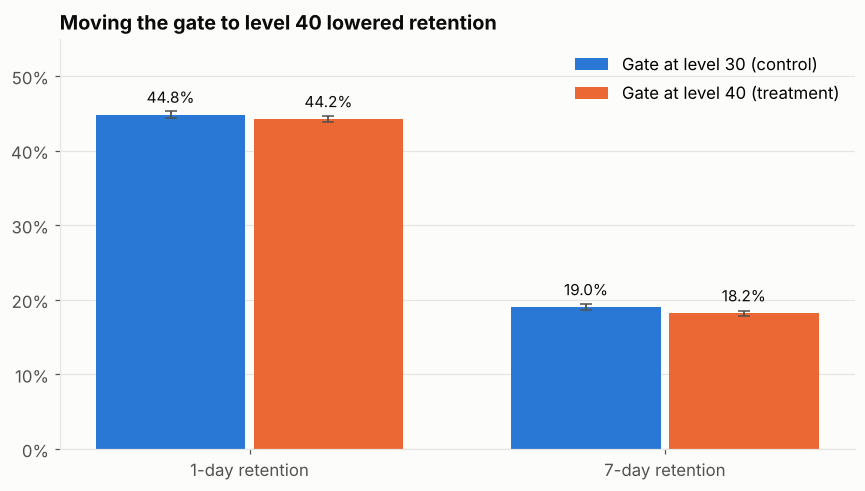

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.6))
labels = ["1-day retention", "7-day retention"]
x = np.arange(2); w = 0.36
b1 = ax.bar(x - w/2 - 0.01, ret.gate_30*100, w, yerr=ret.ci30*100, color=C30, label="Gate at level 30 (control)",
            error_kw=dict(ecolor=INK2, lw=1.2, capsize=4))
b2 = ax.bar(x + w/2 + 0.01, ret.gate_40*100, w, yerr=ret.ci40*100, color=C40, label="Gate at level 40 (treatment)",
            error_kw=dict(ecolor=INK2, lw=1.2, capsize=4))
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x()+b.get_width()/2, b.get_height()+1.6, f"{b.get_height():.1f}%", ha="center", color=INK, fontsize=10)
ax.set_xticks(x, labels); ax.set_ylim(0, 55)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.grid(axis="x", visible=False)
ax.set_title("Moving the gate to level 40 lowered retention")
ax.legend(loc="upper right", ncol=1)
save(fig, "01_retention_ci")

## 5. Bootstrap: how confident are we in the difference?
The z-test relies on a normal approximation. Bootstrapping (resampling players with replacement, 5,000 times) gives the sampling distribution of the difference directly,
without that assumption, and an intuitive probability statement.

In [9]:
B = 5000
boot = {}
for m in ["retention_1", "retention_7"]:
    a = df.loc[df.version=="gate_30", m].values.astype(float)
    b = df.loc[df.version=="gate_40", m].values.astype(float)
    ma = RNG.binomial(len(a), a.mean(), B)/len(a)   # equivalent to resampling a binary column
    mb = RNG.binomial(len(b), b.mean(), B)/len(b)
    d = (ma - mb)*100
    boot[m] = {"diff": d, "ma": ma, "mb": mb}
    print(f"{m}: gate_30 - gate_40 = {d.mean():.2f} pp, 95% CI [{np.percentile(d,2.5):.2f}, {np.percentile(d,97.5):.2f}], "
          f"P(gate_30 > gate_40) = {(d>0).mean():.1%}")
RESULTS["bootstrap"] = {m: {"mean_pp": round(float(v['diff'].mean()),2),
                            "ci": [round(float(np.percentile(v['diff'],2.5)),2), round(float(np.percentile(v['diff'],97.5)),2)],
                            "p_gate30_better": round(float((v['diff']>0).mean()),4)} for m, v in boot.items()}

retention_1: gate_30 - gate_40 = 0.60 pp, 95% CI [-0.06, 1.25], P(gate_30 > gate_40) = 96.2%
retention_7: gate_30 - gate_40 = 0.82 pp, 95% CI [0.31, 1.33], P(gate_30 > gate_40) = 99.9%


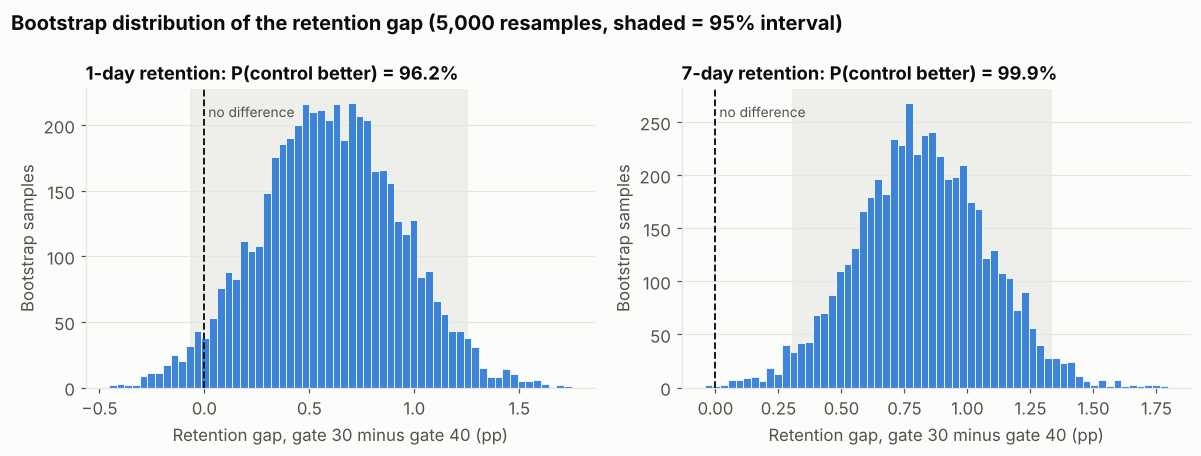

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, m, title in zip(axes, ["retention_1", "retention_7"], ["1-day retention", "7-day retention"]):
    d = boot[m]["diff"]
    ax.hist(d, bins=60, color=C30, alpha=0.9, edgecolor=SURF, linewidth=0.6)
    ax.axvline(0, color=INK, lw=1.2, ls="--"); ax.text(0, ax.get_ylim()[1]*0.95, " no difference", color=INK2, fontsize=9, va="top")
    lo, hi = np.percentile(d, [2.5, 97.5])
    ax.axvspan(lo, hi, color=GRID, alpha=0.6, zorder=0)
    ax.set_title(f"{title}: P(control better) = {(d>0).mean():.1%}", fontsize=12)
    ax.set_xlabel("Retention gap, gate 30 minus gate 40 (pp)"); ax.set_ylabel("Bootstrap samples")
    ax.grid(axis="x", visible=False)
fig.suptitle("Bootstrap distribution of the retention gap (5,000 resamples, shaded = 95% interval)", x=0.01, ha="left", color=INK, fontweight="bold")
save(fig, "02_bootstrap_diff")

## 6. Bayesian view: probability and expected loss
A Beta-Binomial model with a flat Beta(1,1) prior gives the posterior for each group's retention rate.
From it we read off P(gate_30 is better) and the **expected loss** of choosing each option, which is how much retention we expect to give up if we pick it and are wrong.

In [11]:
S = 200_000
bayes = {}
for m in ["retention_1", "retention_7"]:
    k = df.groupby("version")[m].sum().reindex(["gate_30","gate_40"]).values
    pa = RNG.beta(1+k[0], 1+n30-k[0], S); pb = RNG.beta(1+k[1], 1+n40-k[1], S)
    bayes[m] = {"p_gate30_better": float((pa>pb).mean()),
                "loss_choose_40_pp": float(np.maximum(pa-pb,0).mean()*100),
                "loss_choose_30_pp": float(np.maximum(pb-pa,0).mean()*100),
                "diff": (pa-pb)*100}
    print(f"{m}: P(gate_30 better) = {bayes[m]['p_gate30_better']:.2%}; expected loss if we ship gate_40 = "
          f"{bayes[m]['loss_choose_40_pp']:.3f} pp, if we keep gate_30 = {bayes[m]['loss_choose_30_pp']:.4f} pp")
RESULTS["bayes"] = {m: {k2: round(v2, 5) for k2, v2 in v.items() if k2 != "diff"} for m, v in bayes.items()}

retention_1: P(gate_30 better) = 96.27%; expected loss if we ship gate_40 = 0.595 pp, if we keep gate_30 = 0.0050 pp
retention_7: P(gate_30 better) = 99.92%; expected loss if we ship gate_40 = 0.819 pp, if we keep gate_30 = 0.0001 pp


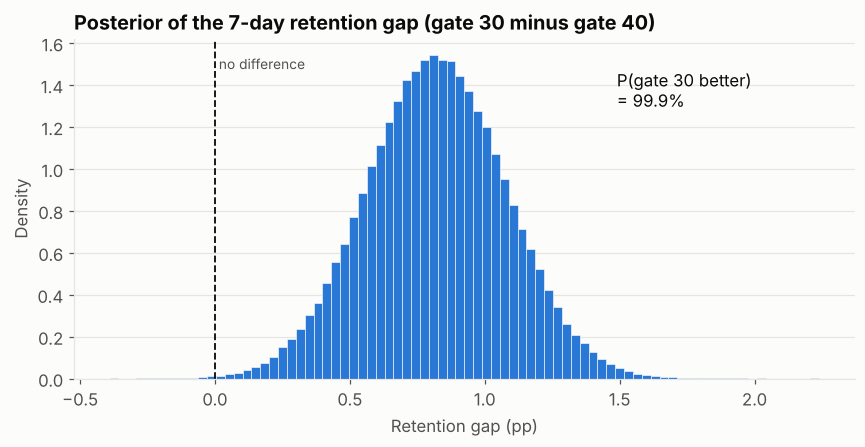

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.2))
d = bayes["retention_7"]["diff"]
ax.hist(d, bins=80, color=C30, edgecolor=SURF, linewidth=0.4, density=True)
ax.axvline(0, color=INK, ls="--", lw=1.2)
ax.text(np.percentile(d, 99.5), ax.get_ylim()[1]*0.8, f"P(gate 30 better)\n= {(d>0).mean():.1%}", color=INK, fontsize=11, ha="left")
ax.text(0, ax.get_ylim()[1]*0.95, " no difference", color=INK2, fontsize=9, va="top")
ax.set_title("Posterior of the 7-day retention gap (gate 30 minus gate 40)")
ax.set_xlabel("Retention gap (pp)"); ax.set_ylabel("Density"); ax.grid(axis="x", visible=False)
save(fig, "03_bayesian_posterior")

## 7. Secondary metric: engagement (game rounds)
Game rounds are extremely right-skewed (many players play a handful of rounds, a few play thousands), so a t-test on means is fragile.
The Mann-Whitney U test compares the distributions by rank, and a bootstrap gives a CI on the median difference.

In [13]:
g30 = df_r.loc[df_r.version=="gate_30","sum_gamerounds"].values
g40 = df_r.loc[df_r.version=="gate_40","sum_gamerounds"].values
u, p_mw = stats.mannwhitneyu(g30, g40, alternative="two-sided")
t, p_welch = stats.ttest_ind(g30, g40, equal_var=False)
med_diff, mean_diff = [], []
for _ in range(2000):
    s30 = RNG.choice(g30, len(g30)); s40 = RNG.choice(g40, len(g40))
    med_diff.append(np.median(s30) - np.median(s40)); mean_diff.append(s30.mean() - s40.mean())
med_diff, mean_diff = np.array(med_diff), np.array(mean_diff)
print(f"Median rounds: gate_30 {np.median(g30):.0f}, gate_40 {np.median(g40):.0f}")
print(f"Mean rounds:   gate_30 {g30.mean():.2f}, gate_40 {g40.mean():.2f}")
print(f"Mann-Whitney p = {p_mw:.4f} | Welch t-test p = {p_welch:.4f}")
print(f"Bootstrap mean diff 95% CI: [{np.percentile(mean_diff,2.5):.2f}, {np.percentile(mean_diff,97.5):.2f}] rounds")
print(f"Bootstrap median diff 95% CI: [{np.percentile(med_diff,2.5):.1f}, {np.percentile(med_diff,97.5):.1f}] rounds")
RESULTS["rounds"] = {"median_30": float(np.median(g30)), "median_40": float(np.median(g40)),
                     "mean_30": round(float(g30.mean()),2), "mean_40": round(float(g40.mean()),2),
                     "p_mannwhitney": round(float(p_mw),4), "p_welch": round(float(p_welch),4),
                     "mean_diff_ci": [round(float(np.percentile(mean_diff,2.5)),2), round(float(np.percentile(mean_diff,97.5)),2)]}

Median rounds: gate_30 17, gate_40 16
Mean rounds:   gate_30 51.34, gate_40 51.30
Mann-Whitney p = 0.0509 | Welch t-test p = 0.9495
Bootstrap mean diff 95% CI: [-1.32, 1.36] rounds
Bootstrap median diff 95% CI: [0.0, 1.0] rounds


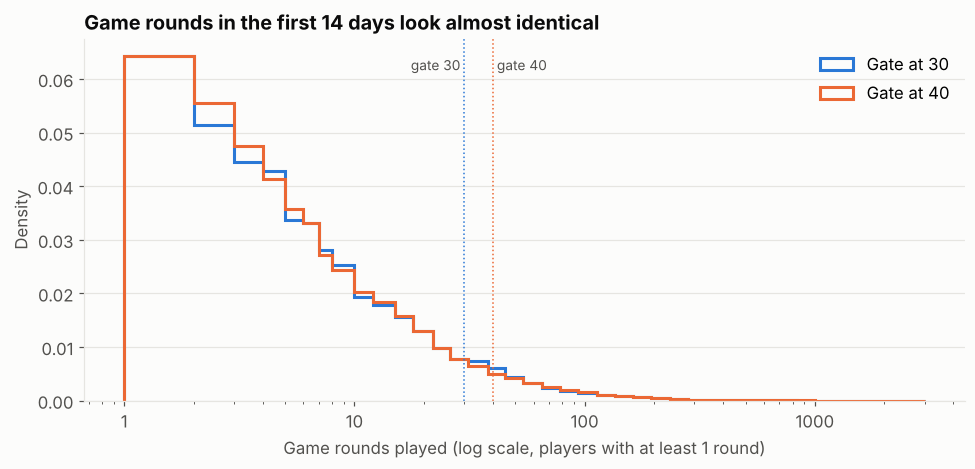

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.4))
bins = np.unique(np.logspace(0, np.log10(3000), 45).astype(int))
for g, c, lab in [(g30, C30, "Gate at 30"), (g40, C40, "Gate at 40")]:
    ax.hist(g[g>0], bins=bins, histtype="step", lw=2, color=c, label=lab, density=True)
ax.set_xscale("log"); ax.xaxis.set_major_formatter(mtick.ScalarFormatter())
ax.axvline(30, color=C30, lw=1, ls=":"); ax.axvline(40, color=C40, lw=1, ls=":")
ax.text(30, ax.get_ylim()[1]*0.95, "gate 30 ", ha="right", color=INK2, fontsize=9, va="top")
ax.text(40, ax.get_ylim()[1]*0.95, " gate 40", ha="left", color=INK2, fontsize=9, va="top")
ax.set_title("Game rounds in the first 14 days look almost identical")
ax.set_xlabel("Game rounds played (log scale, players with at least 1 round)"); ax.set_ylabel("Density")
ax.legend(loc="upper right"); ax.grid(axis="x", visible=False)
save(fig, "04_rounds_distribution")

## 8. Segment view: retention by engagement level
Where does the gap come from? Bucketing players by rounds played shows how retention varies by engagement.

**Caution:** rounds played is measured *after* assignment and is itself affected by the gate, so these segments are descriptive, not causal. They help form hypotheses, not prove them.

In [15]:
buckets = [-1, 0, 10, 29, 39, 60, 100, 200, np.inf]
blabels = ["0", "1-10", "11-29", "30-39", "40-60", "61-100", "101-200", "200+"]
df["rounds_bucket"] = pd.cut(df.sum_gamerounds, buckets, labels=blabels)
seg = df.groupby(["rounds_bucket","version"], observed=True).agg(players=("userid","count"), ret_7=("retention_7","mean")).reset_index()
seg_p = seg.pivot(index="rounds_bucket", columns="version", values=["players","ret_7"])
seg_p

players              ret_7          
version        gate_30  gate_40   gate_30   gate_40
rounds_bucket                                      
0               1937.0   2057.0  0.008260  0.006320
1-10           15736.0  16259.0  0.019319  0.019374
11-29          10371.0  10560.0  0.084273  0.076420
30-39           3090.0   2786.0  0.157282  0.156856
40-60           3939.0   3792.0  0.255649  0.225738
61-100          3532.0   3745.0  0.414496  0.365821
101-200         3490.0   3672.0  0.612894  0.614107
200+            2605.0   2618.0  0.849136  0.850267

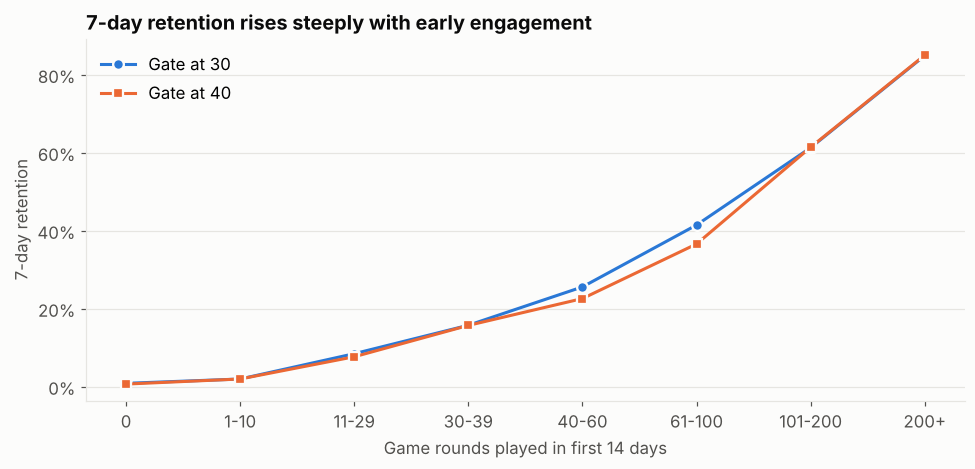

In [16]:
fig, ax = plt.subplots(figsize=(9, 4.4))
for v, c, lab, mk in [("gate_30", C30, "Gate at 30", "o"), ("gate_40", C40, "Gate at 40", "s")]:
    s = seg[seg.version==v]
    ax.plot(s.rounds_bucket.astype(str), s.ret_7*100, color=c, lw=2, marker=mk, ms=7, label=lab,
            markeredgecolor=SURF, markeredgewidth=1.5)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("7-day retention rises steeply with early engagement")
ax.set_xlabel("Game rounds played in first 14 days"); ax.set_ylabel("7-day retention")
ax.legend(loc="upper left"); ax.grid(axis="x", visible=False)
save(fig, "05_retention_by_engagement")

## 9. Multiple-testing correction
Three hypotheses were tested (1-day retention, 7-day retention, game rounds). Holm's step-down correction controls the family-wise error rate at 5%.

In [17]:
pvals = [ret.loc[0,"p_value"], ret.loc[1,"p_value"], p_mw]
reject, p_adj, _, _ = multipletests(pvals, alpha=0.05, method="holm")
mt = pd.DataFrame({"test": ["1-day retention", "7-day retention", "Game rounds (Mann-Whitney)"],
                   "raw_p": pvals, "holm_p": p_adj, "significant": reject})
RESULTS["holm"] = mt.round(5).to_dict(orient="records")
mt.round(4)

,test,raw_p,holm_p,significant
0,1-day retention,0.0744,0.1018,False
1,7-day retention,0.0016,0.0047,True
2,Game rounds (Mann-Whitney),0.0509,0.1018,False


## 10. Why you must not "peek": an A/A simulation
A common mistake is checking the p-value every day and stopping as soon as it drops below 0.05.
To show the cost, I simulate **1,000 A/A tests** (both groups have the true 7-day retention of this experiment, so any "win" is a false positive),
each with 90,000 players arriving over 14 days, and compare a single test at the end with checking every day.

In [18]:
p_true = df.retention_7.mean(); n_per_day = 90_000 // 14 // 2; days = 14; sims = 1000
fixed_fp, peek_fp = 0, 0
example_paths = []
for s in range(sims):
    a = RNG.binomial(n_per_day, p_true, days).cumsum(); b = RNG.binomial(n_per_day, p_true, days).cumsum()
    n = n_per_day*np.arange(1, days+1)
    pa, pb = a/n, b/n; pp = (a+b)/(2*n)
    z = (pa-pb)/np.sqrt(pp*(1-pp)*2/n); pv = 2*(1-stats.norm.cdf(np.abs(z)))
    fixed_fp += pv[-1] < 0.05; peek_fp += (pv < 0.05).any()
    if s < 40: example_paths.append(pv)
RESULTS["peeking"] = {"fixed_fpr": fixed_fp/sims, "peek_fpr": peek_fp/sims}
print(f"False positive rate, single test at day 14: {fixed_fp/sims:.1%}")
print(f"False positive rate, stop at first daily p < 0.05: {peek_fp/sims:.1%}")

False positive rate, single test at day 14: 4.2%
False positive rate, stop at first daily p < 0.05: 21.5%


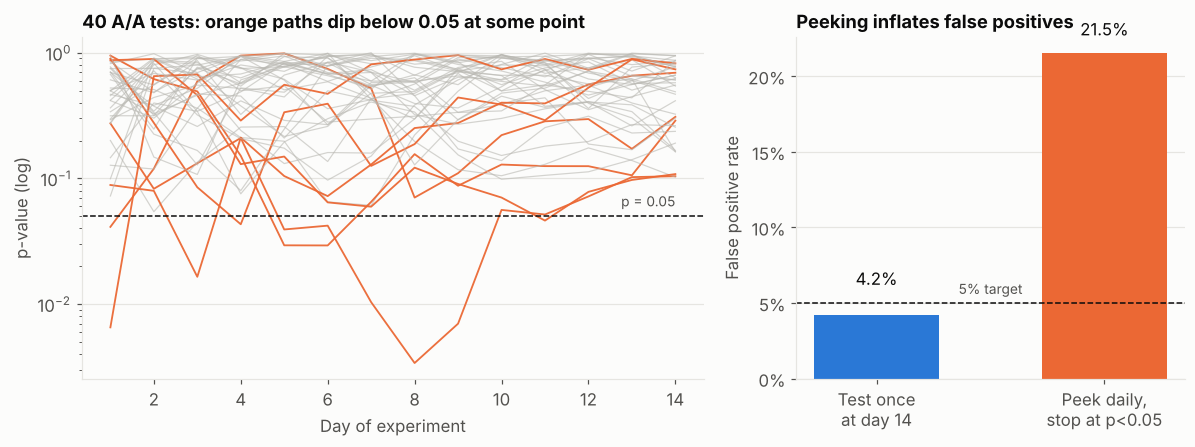

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios":[1.6,1]})
for pv in example_paths:
    hit = (pv < 0.05).any()
    ax1.plot(range(1, 15), pv, color=C40 if hit else "#b9b8b2", lw=1.2 if hit else 0.8, alpha=0.95 if hit else 0.6)
ax1.axhline(0.05, color=INK, ls="--", lw=1); ax1.text(14, 0.06, "p = 0.05", ha="right", color=INK2, fontsize=9)
ax1.set_yscale("log"); ax1.set_xlabel("Day of experiment"); ax1.set_ylabel("p-value (log)")
ax1.set_title("40 A/A tests: orange paths dip below 0.05 at some point", fontsize=12); ax1.grid(axis="x", visible=False)
vals = [RESULTS["peeking"]["fixed_fpr"]*100, RESULTS["peeking"]["peek_fpr"]*100]
bars = ax2.bar(["Test once\nat day 14", "Peek daily,\nstop at p<0.05"], vals, color=[C30, C40], width=0.55)
for b, v in zip(bars, vals): ax2.text(b.get_x()+b.get_width()/2, max(v, 5)+1.2, f"{v:.1f}%", ha="center", color=INK)
ax2.axhline(5, color=INK, ls="--", lw=1); ax2.text(0.5, 5.6, "5% target", ha="center", color=INK2, fontsize=9)
ax2.set_ylabel("False positive rate"); ax2.set_title("Peeking inflates false positives", fontsize=12); ax2.grid(axis="x", visible=False)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
save(fig, "06_peeking_simulation")

## 11. Conclusion and recommendation

In [20]:
r1, r7 = ret.iloc[0], ret.iloc[1]
print(f"1-day retention: gate_30 {r1.gate_30:.2%} vs gate_40 {r1.gate_40:.2%} (diff {r1.diff_pp:+.2f} pp, p = {r1.p_value:.3f})")
print(f"7-day retention: gate_30 {r7.gate_30:.2%} vs gate_40 {r7.gate_40:.2%} (diff {r7.diff_pp:+.2f} pp, "
      f"95% CI [{r7.ci_lo_pp:.2f}, {r7.ci_hi_pp:.2f}], p = {r7.p_value:.4f})")
RESULTS["retention"] = ret.drop(columns=["ci30","ci40"]).round(6).to_dict(orient="records")
with open("results.json", "w") as f: json.dump(RESULTS, f, indent=2, default=float)

1-day retention: gate_30 44.82% vs gate_40 44.23% (diff -0.59 pp, p = 0.074)
7-day retention: gate_30 19.02% vs gate_40 18.20% (diff -0.82 pp, 95% CI [-1.33, -0.31], p = 0.0016)


**Recommendation: keep the gate at level 30.**

- **7-day retention**, the primary metric, is lower with the gate at level 40. The drop is statistically significant, survives the Holm correction, and the bootstrap and Bayesian views agree that the control is almost certainly better.
- **1-day retention** points the same way but the difference is not significant, which fits the mechanism: most players have not reached level 30 or 40 by day 1.
- **Engagement** (game rounds) shows no meaningful difference, so moving the gate did not buy extra play in exchange for the retention loss.
- **Likely mechanism:** an earlier forced break may act as a pacing device (hedonic adaptation). Players who are made to pause come back fresher, rather than burning out.

**Caveats**
- The sample ratio check flags a small imbalance (49.6/50.4). In production I would fix or explain this before shipping a decision.
- No pre-experiment covariates are available, so variance reduction (CUPED) and covariate balance checks are not possible on this dataset.
- Retention is measured once per player; revenue impact (gate purchases) is not in the data, and a full decision should weigh it.